# 07 — Data review and labelling (Lustre / Python 3.9 version)

Same analysis as `07_data_review_and_labelling.ipynb`, adapted to run on this cluster:
- `DATA_ROOT` auto-detected (Lustre path first, then `/data/...`; override with env var `FA_DATA_ROOT`).
- `tomllib` falls back to `tomli` (the venv is Python 3.9).
- Chunk reads run in parallel (`joblib`, `N_JOBS` processes) — Lustre likes many concurrent readers.
- The bad-data and quality checks share **one pass** over all chunks (each file opened once), cached to `results/data_labelling/.chunk_scan_cache.pkl`.
- BCM_GUN is loaded once and reused by all plots.
- Outputs go to `results/data_labelling/`; the stitched acquisition (one row per shot: run, chunk, segment, file)
  is saved as `stitched_index.csv` for `07_02`.

In [1]:
import ast
import json
import os
import pickle
from collections import Counter
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from joblib import Parallel, delayed

try:
    import tomllib                 # Python >= 3.11
except ModuleNotFoundError:
    import tomli as tomllib        # Python 3.9 venv on this cluster

DATA_CANDIDATES = [
    os.environ.get("FA_DATA_ROOT"),
    "/lustre/work/pdl18409/shared/data/optimisation/measured_data",
    "/data/optimisation/measured_data",
]
DATA_ROOT = next(Path(p) for p in DATA_CANDIDATES if p and Path(p).is_dir())  # folder that contains the acquisition_* runs
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = REPO / "results" / "data_labelling"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(32, os.cpu_count() or 1)   # shared node: don't take all 128 cores
print(f"DATA_ROOT = {DATA_ROOT}\nOUT = {OUT}\nN_JOBS = {N_JOBS}")


def pmap(fn, items, *args):
    """[fn(x, *args) for x in items], in parallel processes, order preserved."""
    items = list(items)
    if len(items) < 4:
        return [fn(x, *args) for x in items]
    return Parallel(n_jobs=N_JOBS)(delayed(fn)(x, *args) for x in items)


def find_chunks(root=DATA_ROOT):
    """{run name: sorted list of chunk paths} for every acquisition_*/h5/chunk_*.h5 under root."""
    runs = {}
    for run in sorted(root.glob("acquisition_*")):
        chunks = sorted((run / "h5").glob("chunk_*.h5"))
        if chunks:
            runs[run.name] = chunks
    return runs


def is_ragged(obj):
    return isinstance(obj, h5py.Group) and bool(obj.attrs.get("ragged", False))


def list_variables(f):
    """All variable names in a chunk (path or open h5py.File); a ragged group counts as one variable."""
    if not isinstance(f, h5py.File):
        with h5py.File(f, "r") as g:
            return list_variables(g)
    names = []

    def visit(name, obj):
        parent = name.rsplit("/", 1)[0] if "/" in name else ""
        if parent and is_ragged(f[parent]):
            return
        if isinstance(obj, h5py.Dataset) or is_ragged(obj):
            names.append(name)

    f.visititems(visit)
    return names


def decode(x):
    """bytes -> str; pyda reprs stored as text -> their value (Boolean -> bool, EnumItem -> name)."""
    if not isinstance(x, bytes):
        return x
    s = x.decode()
    if s.startswith("pyda.data.Boolean"):
        return ast.literal_eval(s.split("'value': ")[1].split(",")[0])
    if s.startswith("pyda.data.EnumItem"):
        return s.split("'name': ")[1].split("'")[1]
    return s


def read_variable(f, name):
    """One chunk's array of a variable, shot on axis 0. Ragged groups are NaN-padded to the longest shot."""
    obj = f[name]
    if isinstance(obj, h5py.Dataset):
        a = obj[()]
    else:
        shots = [obj[k][()] for k in sorted(obj)]
        out = np.full((len(shots), max(len(s) for s in shots)), np.nan)
        for i, s in enumerate(shots):
            out[i, : len(s)] = s
        a = out
    if a.dtype.kind in "OS":
        a = np.array([decode(x) for x in a], dtype=object)
    return a


def _pad(a, width):
    """NaN-pad axis 1 to width (ragged lengths can differ between chunks)."""
    if a.ndim < 2 or a.shape[1] == width:
        return a
    out = np.full((a.shape[0], width, *a.shape[2:]), np.nan)
    out[:, : a.shape[1]] = a
    return out


def _read_or_count(fp, variable):
    """Worker: the variable's array from one chunk, or its n_shots if the variable is absent."""
    with h5py.File(fp, "r") as f:
        return read_variable(f, variable) if variable in f else int(f.attrs["n_shots"])


def load_dataset(path, variable, squeeze=True):
    """
    Full array of one variable, shots concatenated in chunk order (chunks read in parallel).
    path: a chunk file, a run folder (acquisition_*), a run name from find_chunks(), or a list of chunk files.
    Chunks without the variable are filled with NaN (None for strings). squeeze=True turns (n, 1, L) into (n, L).
    Beware: BTV0125/image2D is ~470 MB per chunk.
    """
    if isinstance(path, (list, tuple)):
        files = [Path(p) for p in path]
    else:
        p = Path(path)
        if not p.exists():
            p = DATA_ROOT / p                        # run name only
        files = sorted((p / "h5").glob("chunk_*.h5")) if p.is_dir() else [p]
    if not files:
        raise FileNotFoundError(f"no chunks for {path}")

    parts = pmap(_read_or_count, files, variable)
    missing = [fp.name for fp, a in zip(files, parts) if isinstance(a, int)]
    arrays = [a for a in parts if isinstance(a, np.ndarray)]
    if not arrays:
        raise KeyError(f"{variable} not in any of {len(files)} chunk(s)")
    if missing:
        print(f"{variable}: missing in {len(missing)} chunk(s), filled: {missing}")
    ref = arrays[0]
    width = max(a.shape[1] for a in arrays) if ref.ndim > 1 else None
    fill = np.nan if ref.dtype.kind in "fiu" else None
    parts = [np.full((a, *ref.shape[1:]), fill, dtype=float if fill is not None else object)
             if isinstance(a, int) else a for a in parts]
    out = np.concatenate([_pad(a, width) for a in parts]) if width else np.concatenate(parts)
    if squeeze and out.ndim == 3 and out.shape[1] == 1:
        out = out[:, 0]
    return out


runs = find_chunks()
for name, chunks in runs.items():
    print(f"{name}: {len(chunks)} chunks")

DATA_ROOT = /lustre/work/pdl18409/shared/data/optimisation/measured_data
OUT = /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/data_labelling
N_JOBS = 32
acquisition_2026-10-06_21-57-43: 226 chunks
acquisition_2026-10-07_20-55-58: 5 chunks
acquisition_2026-10-07_21-42-34: 1 chunks
acquisition_2026-10-07_21-43-26: 72 chunks
acquisition_2026-10-08_00-08-19: 255 chunks
acquisition_2026-10-08_15-42-27: 121 chunks
acquisition_2026-10-08_21-11-47: 200 chunks
acquisition_2026-10-09_07-46-07: 110 chunks
acquisition_2026-10-09_11-48-33: 186 chunks


In [2]:
name_map = list(runs)
print(name_map)

['acquisition_2026-10-06_21-57-43', 'acquisition_2026-10-07_20-55-58', 'acquisition_2026-10-07_21-42-34', 'acquisition_2026-10-07_21-43-26', 'acquisition_2026-10-08_00-08-19', 'acquisition_2026-10-08_15-42-27', 'acquisition_2026-10-08_21-11-47', 'acquisition_2026-10-09_07-46-07', 'acquisition_2026-10-09_11-48-33']


In [3]:
# BCM_GUN for every run, loaded once (parallel) and reused below
bcm = {run: load_dataset(run, "BCM_GUN") for run in runs}

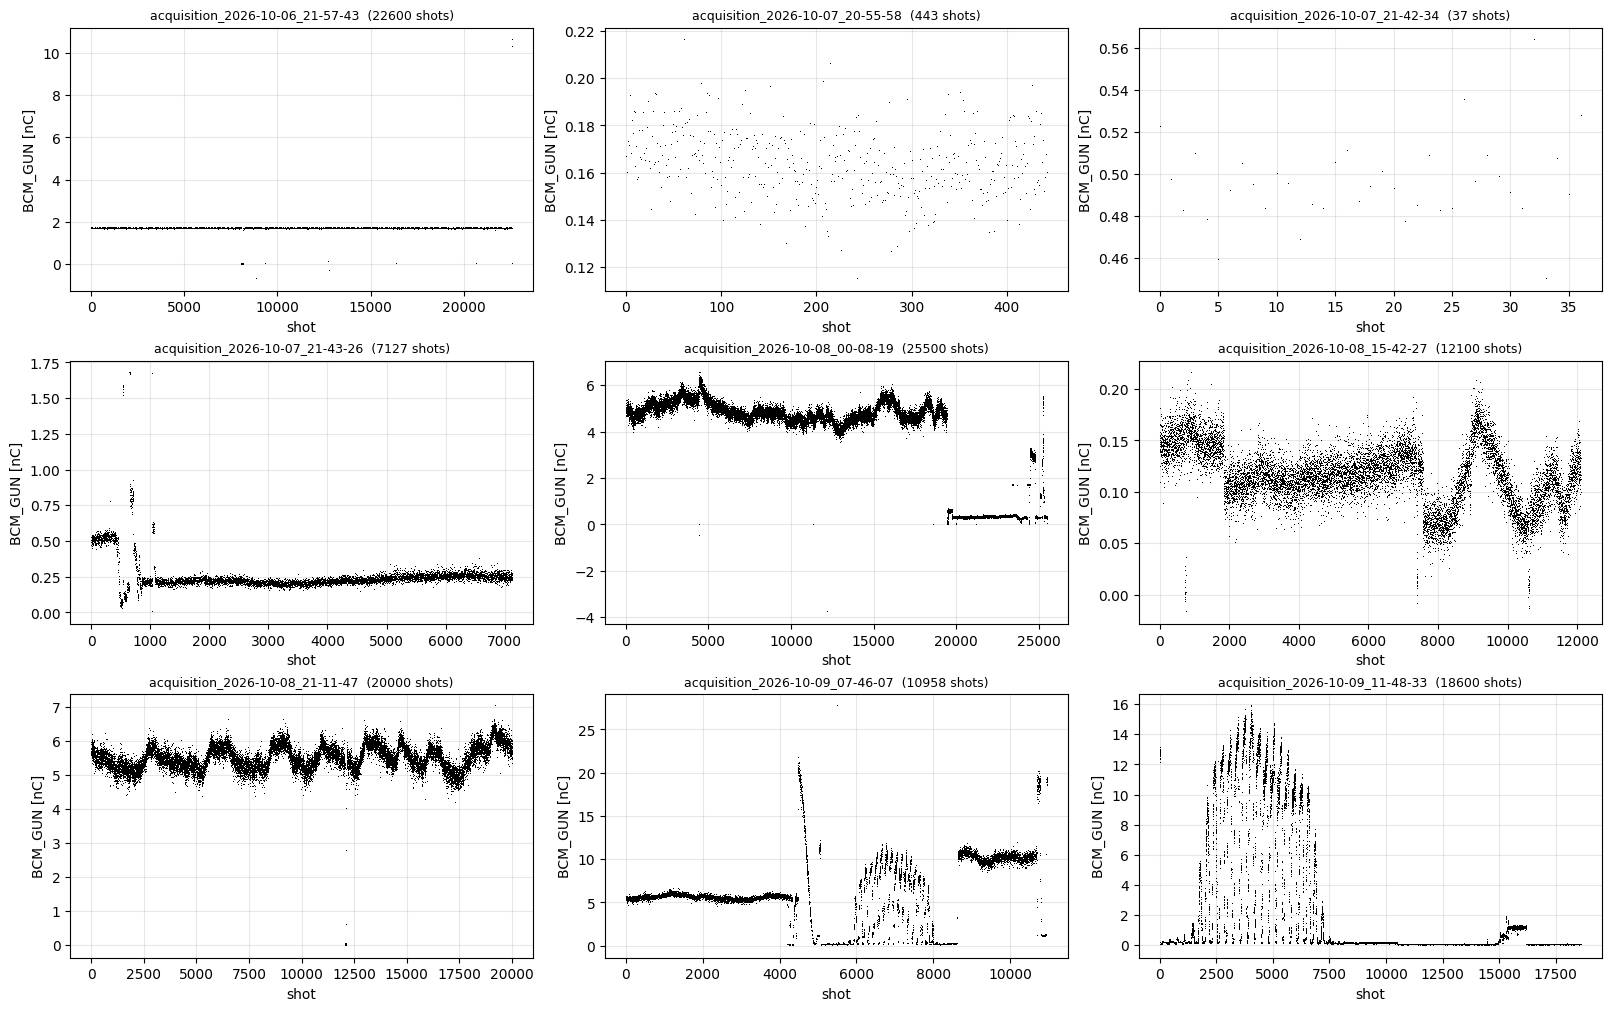

In [4]:
# charge evolution for all runs
fig, axes = plt.subplots(3, 3, figsize=(16, 10), constrained_layout=True)
for ax, run in zip(axes.flat, runs):
    q = bcm[run]
    ax.plot(q, ",", color="k")
    ax.set_title(f"{run}  ({len(q)} shots)", fontsize=9)
    ax.set_xlabel("shot")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(runs):]:   # hide unused panels if fewer than 9 runs
    ax.set_visible(False)

fig.savefig(OUT / "bcm_runs.png", dpi=150, bbox_inches="tight")
plt.show()

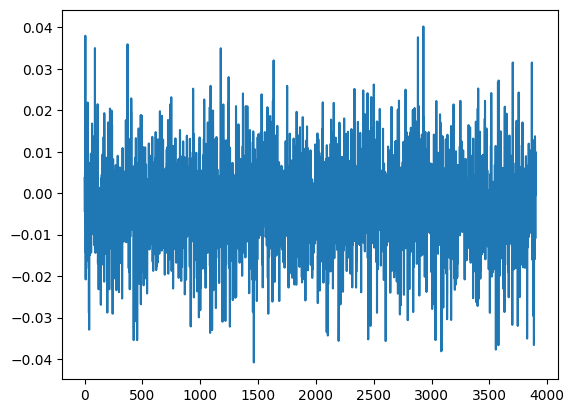

In [5]:
# cut a dataset to only keep the good data

# manually check where to cut...
q = bcm[name_map[8]]
plt.plot(q[10500:14400])

In [6]:
def clean_chunks(cuts_file=REPO / "config" / "CLEAN_CUTS.toml", root=DATA_ROOT):
    """{run: [chunk paths to use]} from the CLEAN_CUTS file; warns about listed chunks that do not exist."""
    with open(cuts_file, "rb") as f:
        cuts = tomllib.load(f)
    out = {}
    for run, spec in cuts.items():
        files = {int(p.stem[6:]): p for p in sorted((root / run / "h5").glob("chunk_*.h5"))}
        if spec["keep"] == "all":
            wanted = sorted(files)
        else:
            wanted = [i for a, b in spec["keep"] for i in range(a, b + 1)]
        absent = [i for i in wanted if i not in files]
        if absent:
            print(f"{run}: listed but not found: chunks {absent}")
        out[run] = [files[i] for i in wanted if i in files]
    return out


clean = clean_chunks()
for run, chunks in clean.items():
    print(f"{run}: {len(chunks)} clean chunks")

acquisition_2026-10-07_21-43-26: 61 clean chunks
acquisition_2026-10-08_00-08-19: 194 clean chunks
acquisition_2026-10-08_15-42-27: 118 clean chunks
acquisition_2026-10-08_21-11-47: 200 clean chunks
acquisition_2026-10-09_07-46-07: 61 clean chunks


634 chunks, 63327 shots from 5 runs, 8 segments


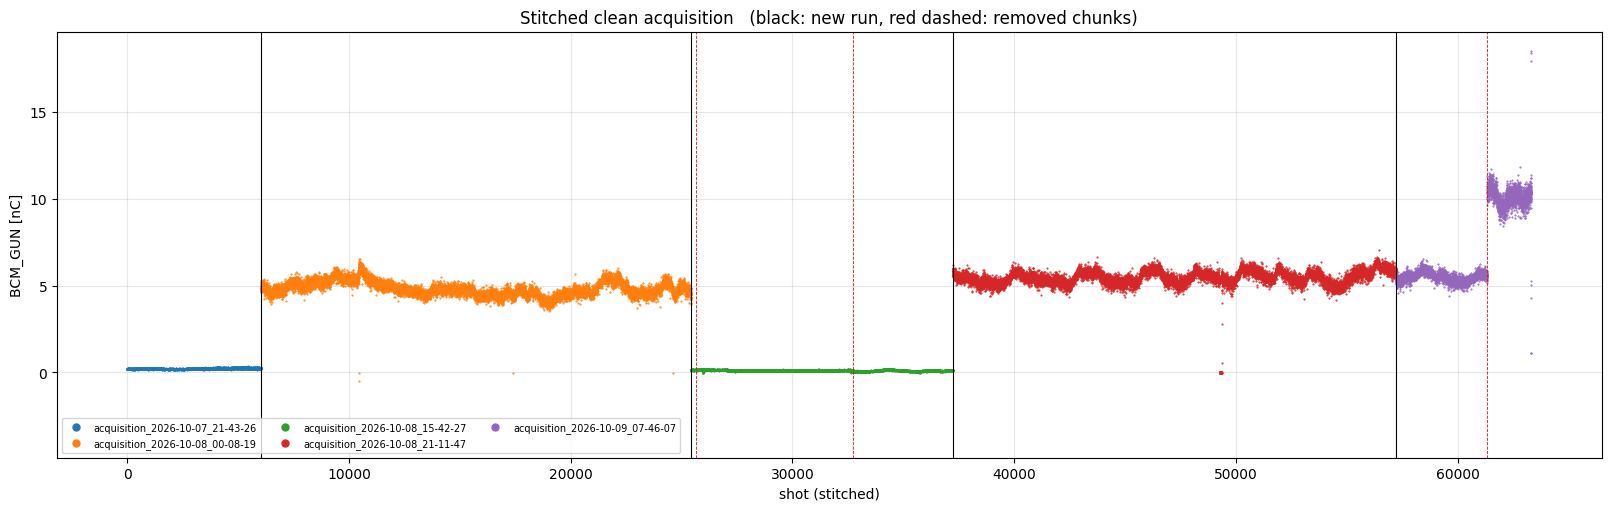

In [7]:
def _n_shots(fp):
    with h5py.File(fp, "r") as f:
        return int(f.attrs["n_shots"])


def stitch(clean):
    """One virtual acquisition from the clean chunks of all runs, in run order. Per-shot run and chunk labels."""
    files = [p for run in sorted(clean) for p in clean[run]]
    ns = pmap(_n_shots, files)
    run_of = np.concatenate([[p.parent.parent.name] * n for p, n in zip(files, ns)])
    chunk_of = np.concatenate([[int(p.stem[6:])] * n for p, n in zip(files, ns)])
    new_run = np.flatnonzero(run_of[1:] != run_of[:-1]) + 1                  # first shot of the next run
    cut = np.flatnonzero((run_of[1:] == run_of[:-1]) & ~np.isin(np.diff(chunk_of), (0, 1))) + 1  # removed chunks in between
    segment = np.zeros(len(run_of), dtype=int)                               # contiguous stretch id
    segment[np.union1d(new_run, cut)] = 1
    segment = np.cumsum(segment)
    file_of = np.concatenate([[str(p)] * n for p, n in zip(files, ns)])
    shot_in_chunk = np.concatenate([np.arange(n) for n in ns])
    return {"files": files, "run": run_of, "chunk": chunk_of, "new_run": new_run, "cut": cut,
            "segment": segment, "file": file_of, "shot_in_chunk": shot_in_chunk}


st = stitch(clean)
q = load_dataset(st["files"], "BCM_GUN")
x = np.arange(len(q))
print(f"{len(st['files'])} chunks, {len(q)} shots from {len(clean)} runs, {st['segment'].max() + 1} segments")

# the stitched acquisition, one row per shot (used by 07_02)
import pandas as pd
pd.DataFrame({"run": st["run"], "chunk": st["chunk"], "shot_in_chunk": st["shot_in_chunk"],
              "segment": st["segment"], "file": st["file"], "BCM_GUN": q}
             ).to_csv(OUT / "stitched_index.csv", index_label="shot")

fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
for i, run in enumerate(sorted(clean)):
    m = st["run"] == run
    ax.plot(x[m], q[m], ".", ms=1, color=f"C{i % 10}", label=run)
for b in st["new_run"]:
    ax.axvline(b, color="k", lw=0.8)
for b in st["cut"]:
    ax.axvline(b, color="r", lw=0.6, ls="--")
ax.set_xlabel("shot (stitched)")
ax.set_ylabel("BCM_GUN [nC]")
ax.set_title("Stitched clean acquisition   (black: new run, red dashed: removed chunks)")
ax.legend(fontsize=7, markerscale=10, ncol=3, loc="lower left")
ax.grid(alpha=0.3)
fig.savefig(OUT / "stitched_bcm.png", dpi=150, bbox_inches="tight")
plt.show()

## Bad data and quality checks — one parallel pass over all chunks

`scan_chunk` opens each file once and returns everything both reports need; the chunk-boundary
comparisons (stale stamp / repeated waveform vs. the previous chunk's last shot) are done afterwards,
in chunk order. Results are cached per file (path, size, mtime), so re-running is instant.

In [8]:
SKIP_VARS = ("BTV0125/image2D",)  # int16 images: cannot hold NaN, and ~470 MB per chunk to read
MIN_WAVE_LEN = 10                 # per-shot arrays at least this long count as waveforms
CACHE = OUT / ".chunk_scan_cache.pkl"


def bad_rows(obj, n):
    """Number of shots with no usable value: NaN/inf anywhere in the shot, empty ragged shot, empty string."""
    if is_ragged(obj):
        return sum(obj[k].size == 0 or not np.isfinite(obj[k][()]).all() for k in obj)
    if obj.dtype.kind in "iub":                       # integers/bools cannot be NaN
        return 0
    a = obj[()].reshape(n, -1)
    if a.dtype.kind == "f":
        return int((~np.isfinite(a)).any(axis=1).sum())
    return int(np.isin(a, [b"", b"None", b"nan"]).any(axis=1).sum())  # strings


def is_waveform(obj, var):
    """Float dataset with a per-shot array of >= MIN_WAVE_LEN samples (images skipped)."""
    return (isinstance(obj, h5py.Dataset) and obj.dtype.kind == "f" and var not in SKIP_VARS
            and obj.ndim > 1 and np.prod(obj.shape[1:]) >= MIN_WAVE_LEN)


def scan_chunk(fp):
    """
    Worker, one chunk:
      n, names        : n_shots, variable names (SKIP_VARS excluded)
      bad[var]        : shots with no usable value
      stamps[var]     : (first, last, # shots whose stamp equals the previous shot's) for *_stamp
      waves[var]      : first/last shot + within-chunk repeat/zero/flat counts for waveforms
    """
    with h5py.File(fp, "r") as f:
        n = int(f.attrs["n_shots"])
        names = [v for v in list_variables(f) if v not in SKIP_VARS]
        bad = {v: bad_rows(f[v], n) for v in names}
        stamps, waves = {}, {}
        if n:
            for var in f:
                if var.endswith("_stamp") and var != "trigger_stamp":
                    s = f[var][()]
                    stamps[var] = (s[0], s[-1], int((s[1:] == s[:-1]).sum()))
            for var in names:
                if is_waveform(f[var], var):
                    a = f[var][()].reshape(n, -1)
                    waves[var] = {"first": a[:1], "last": a[-1:],
                                  "repeat": int((a[1:] == a[:-1]).all(axis=1).sum()),
                                  "zero": int((a == 0).all(axis=1).sum()),
                                  "flat": int((np.ptp(a, axis=1) == 0).sum())}
    return {"n": n, "names": set(names), "bad": bad, "stamps": stamps, "waves": waves}


def scan_all(files):
    """{path: scan_chunk(path)} using the on-disk cache; only new/changed files are read."""
    cache = {}
    if CACHE.exists():
        with open(CACHE, "rb") as fh:
            cache = pickle.load(fh)
    key = lambda p: (str(p), p.stat().st_size, p.stat().st_mtime)
    todo = [p for p in files if key(p) not in cache]
    print(f"scanning {len(todo)} of {len(files)} chunks ({len(files) - len(todo)} cached)")
    for p, s in zip(todo, Parallel(n_jobs=N_JOBS, verbose=5)(delayed(scan_chunk)(p) for p in todo)):
        cache[key(p)] = s
    if todo:
        with open(CACHE, "wb") as fh:
            pickle.dump(cache, fh)
    return {p: cache[key(p)] for p in files}


scans = scan_all([p for chunks in runs.values() for p in chunks])

scanning 0 of 1176 chunks (1176 cached)


[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.


In [9]:
def bad_data(chunks):
    """{variable: % of shots that are bad} for one run; variables absent from a chunk count as bad there."""
    sc = [scans[p] for p in chunks]
    all_vars = set().union(*(s["names"] for s in sc))
    bad, n_total = Counter(), sum(s["n"] for s in sc)
    for s in sc:
        for var in all_vars:
            bad[var] += s["bad"][var] if var in s["names"] else s["n"]
    return {v: round(100 * c / n_total, 2) for v, c in sorted(bad.items(), key=lambda x: -x[1]) if c}


report = {run: bad_data(chunks) for run, chunks in runs.items()}
print(json.dumps(report, indent=2))

{
  "acquisition_2026-10-06_21-57-43": {
    "BTV0125/imagePositionSet2": 3.04,
    "BTV0125/projDataSet1Original": 3.04,
    "BTV0125/projDataSet1": 3.03,
    "BTV0125/projDataSet2Original": 3.03,
    "BTV0125/projDataSet2": 3.03,
    "BTV0125/imagePositionSet1": 3.02
  },
  "acquisition_2026-10-07_20-55-58": {
    "BTV0125/projDataSet2Original": 10.61,
    "BTV0125/projDataSet2": 10.61,
    "BTV0125/imagePositionSet2": 10.61,
    "BTV0125/projDataSet1Original": 10.61,
    "BTV0125/imagePositionSet1": 10.61,
    "BTV0125/projDataSet1": 10.61
  },
  "acquisition_2026-10-07_21-42-34": {
    "BTV0125/projDataSet2Original": 24.32,
    "BTV0125/projDataSet2": 24.32,
    "BTV0125/imagePositionSet2": 24.32,
    "BTV0125/imagePositionSet1": 24.32,
    "BTV0125/projDataSet1Original": 24.32,
    "BTV0125/projDataSet1": 24.32
  },
  "acquisition_2026-10-07_21-43-26": {
    "BTV0125/imagePositionSet2": 8.28,
    "BTV0125/imagePositionSet1": 8.28,
    "BTV0125/projDataSet2": 8.26,
    "BTV0125/pro

In [10]:
def quality_checks(chunks):
    """
    {variable: {check: % of shots}} for one run, only non-zero entries.
      stale  : stamp equal to the previous shot's stamp (device did not update)
      repeat : waveform identical to the previous shot's waveform
      zero   : waveform all zeros
      flat   : waveform constant (includes zero)
    The previous shot of a chunk's first shot is the last shot of the previous chunk.
    """
    counts, last, n_total = {}, {}, 0
    for p in chunks:
        s = scans[p]
        for var, (first, lst, k) in s["stamps"].items():
            c = counts.setdefault(var.removesuffix("_stamp"), Counter())
            c["stale"] += k + int(var in last and first == last[var])
            last[var] = lst
        for var, w in s["waves"].items():
            c = counts.setdefault(var, Counter())
            prev = last.get(var)
            boundary = prev is not None and prev.shape == w["first"].shape and (prev == w["first"]).all()
            c["repeat"] += w["repeat"] + int(boundary)
            c["zero"] += w["zero"]
            c["flat"] += w["flat"]
            last[var] = w["last"]
        n_total += s["n"]

    report = {}
    for var, c in sorted(counts.items()):
        pct = {k: round(100 * v / n_total, 2) for k, v in c.items() if v}
        if pct:
            report[var] = pct
    return report


quality = {run: quality_checks(chunks) for run, chunks in runs.items()}
print(json.dumps(quality, indent=2))

with open(OUT / "bad_data_report.json", "w") as fh:
    json.dump(report, fh, indent=2)
with open(OUT / "quality_report.json", "w") as fh:
    json.dump(quality, fh, indent=2)

{
  "acquisition_2026-10-06_21-57-43": {
    "BCM_GUN": {
      "stale": 0.0
    },
    "BTV0125": {
      "stale": 0.39
    },
    "BTV0125/imagePositionSet1": {
      "repeat": 11.94
    },
    "BTV0125/imagePositionSet2": {
      "repeat": 11.94
    },
    "BTV0125/projDataSet1": {
      "repeat": 0.01
    },
    "BTV0125/projDataSet1Original": {
      "repeat": 0.01
    },
    "BTV0125/projDataSet2": {
      "repeat": 0.01
    },
    "BTV0125/projDataSet2Original": {
      "repeat": 0.01
    },
    "DHG0130": {
      "stale": 1.5
    },
    "HUMID1": {
      "stale": 2.96
    },
    "HUMID2": {
      "stale": 4.98
    },
    "HUMID3": {
      "stale": 6.26
    },
    "HUMID4": {
      "stale": 7.27
    },
    "PGIA": {
      "stale": 4.88,
      "repeat": 4.92
    },
    "PGIP": {
      "stale": 5.22,
      "repeat": 5.24
    },
    "PGLA": {
      "stale": 5.11
    },
    "PGLA/samples": {
      "repeat": 5.15
    },
    "PGRA": {
      "stale": 4.85,
      "repeat": 4.88
    },
 